In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Da bi se grafikoni lepo prikazivali direktno u Jupyter Notebook-u:
%matplotlib inline
import numpy as np

In [4]:
df = pd.read_csv('clean_data.csv',low_memory=False)

In [5]:
df.head(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,8.55
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,9.39
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,10.75


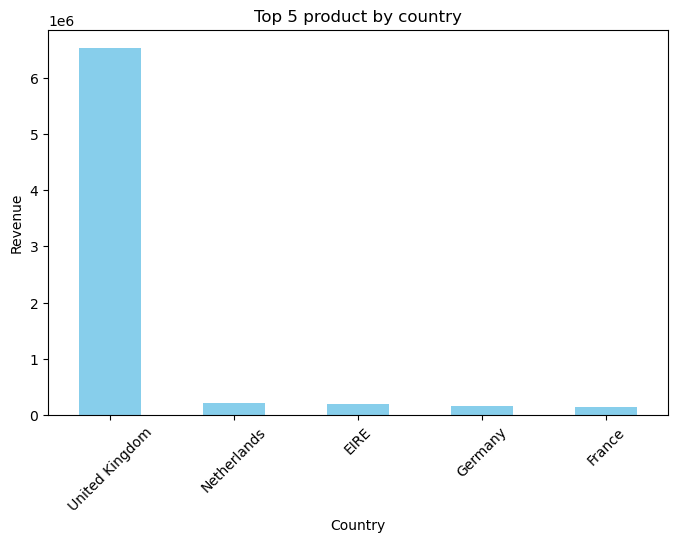

In [9]:
## Top 5 country with highest revenue
top_country = df.groupby('Country')['Revenue'].sum().nlargest(5)

# Crtanje grafikona
plt.figure(figsize=(8, 5))
top_country.plot(kind='bar', color='skyblue')
plt.title('Top 5 product by country')
plt.xlabel('Country')
plt.ylabel('Revenue')
plt.xticks(rotation=45)  # Rotira imena država da se bolje vide
plt.show()

In [ ]:
## The biggest revenue has United Kingdom.

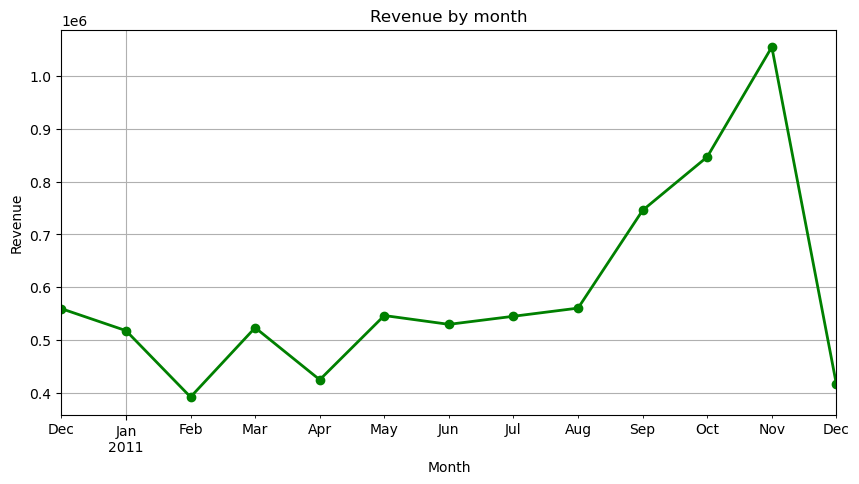

In [11]:
# Convert date in month period and calculate revenue by month
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Month'] = df['InvoiceDate'].dt.to_period('M')
monthly_revenue = df.groupby('Month')['Revenue'].sum()

# Drow line plot
plt.figure(figsize=(10, 5))
monthly_revenue.plot(kind='line', marker='o', color='green', linewidth=2)
plt.title('Revenue by month')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True) 
plt.show()

In [ ]:
## The hiest revenue was in the 3th quartile.

           Quantity  UnitPrice   Revenue
Quantity   1.000000  -0.003773  0.974314
UnitPrice -0.003773   1.000000  0.221519
Revenue    0.974314   0.221519  1.000000


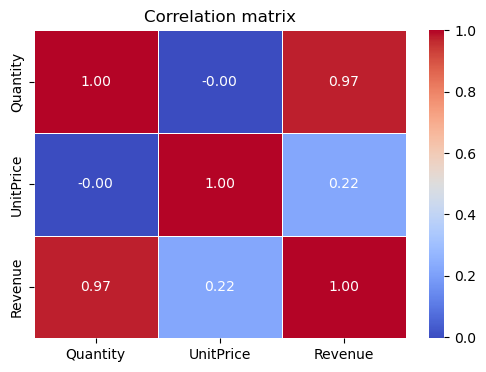

In [12]:
# Calculate coleration only for numerical columns
corelation = df[['Quantity', 'UnitPrice', 'Revenue']].corr()

print(corelation)

# Drow Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corelation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation matrix')
plt.show()

In [ ]:
## Revenue and Quantity strong correlation (0.97), Revenue-UnitPrice (0.22) and quantity-unit price no correlation.

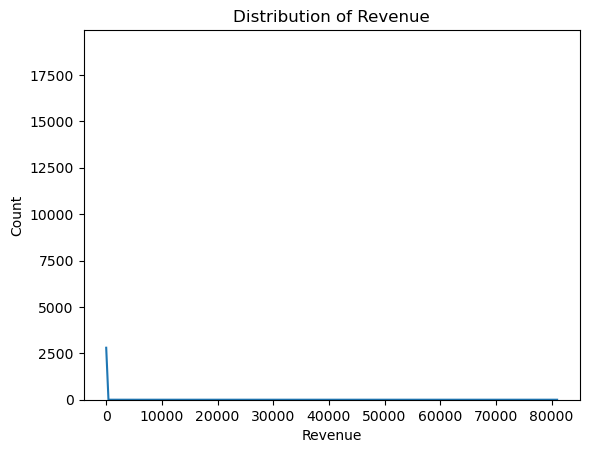

In [13]:
sns.histplot(df["Revenue"], kde=True)
plt.title("Distribution of Revenue")
plt.show()

In [14]:
df["Revenue"].describe()

count    530104.000000
mean         14.449662
std         159.485247
min           1.001000
25%           4.630000
50%           8.250000
75%          13.250000
max       80997.080000
Name: Revenue, dtype: float64

In [ ]:
## Mean is higher than median which indicate positively/right-skewed.
## Most transaction generate relatively low revenue,while small transaction generate long right tail. 

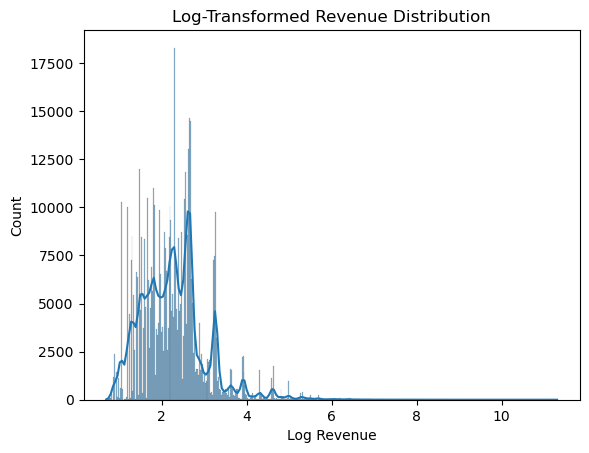

In [17]:
sns.histplot(np.log1p(df["Revenue"]), kde=True)

plt.title("Log-Transformed Revenue Distribution")
plt.xlabel("Log Revenue")
plt.show()

In [ ]:
## This is log scale and may indicate potential outliers/extreme values.

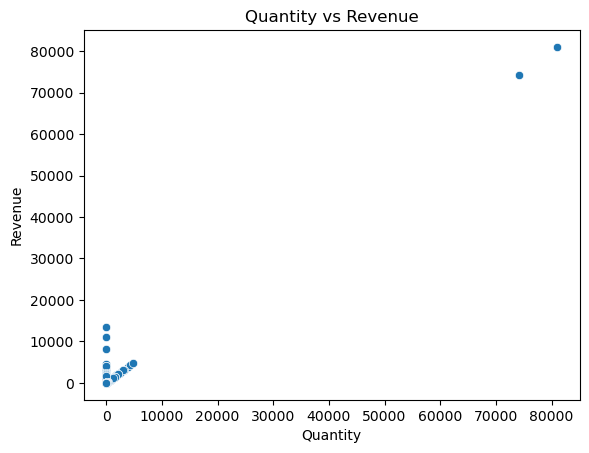

In [18]:
## Below will be scatter plot, because of correlation between Quantity and Revenue.
sns.scatterplot(data=df, x="Quantity", y="Revenue")
plt.title("Quantity vs Revenue")
plt.show()

In [ ]:
## In up-right corner two dots are outlies, those products have drasticaly higher sales volum.


In [19]:
df_filtered = df[(df['Revenue'] < 20000) & (df['Quantity'] < 20000)]

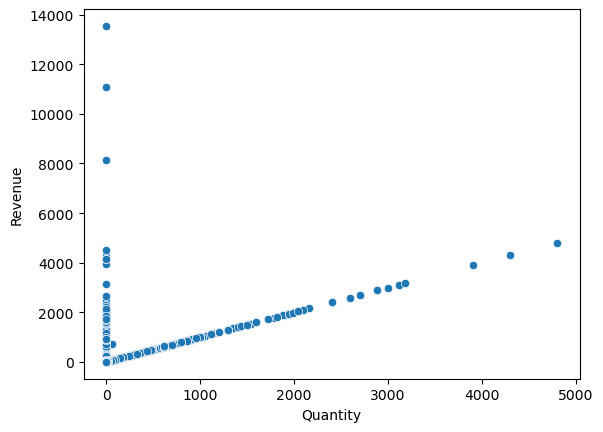

In [20]:
sns.scatterplot(data=df_filtered, x='Quantity', y='Revenue')
plt.show()

In [ ]:
## First direction-vertical could be premium produxts or anomalies in data.
## Horisontal those are products or transactions where relationship between quantity and revenue is linear and constant.

In [21]:
product_revenue = (
    df.groupby("Description")["Revenue"]
      .sum()
      .sort_values(ascending=False)
)

cumulative = product_revenue.cumsum() / product_revenue.sum() * 100


In [24]:
cumulative_products_pct = (
    np.arange(1, len(product_revenue) + 1) / len(product_revenue) * 100
)

<Figure size 1000x600 with 0 Axes>

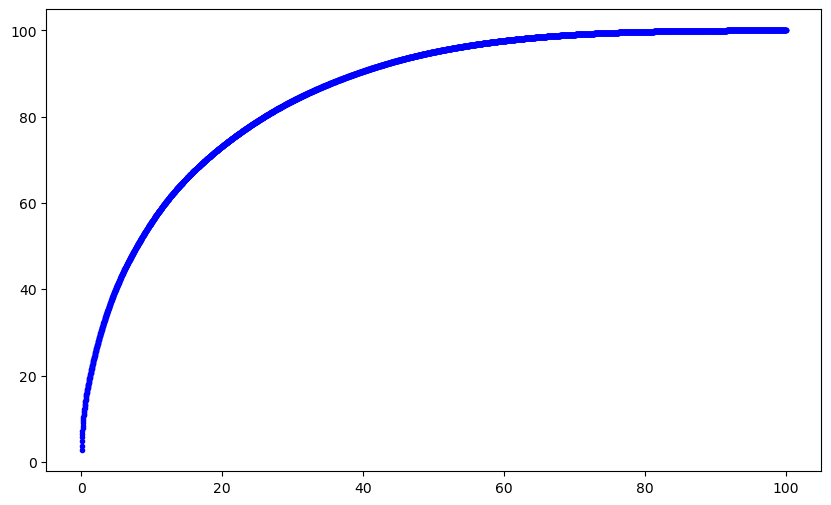

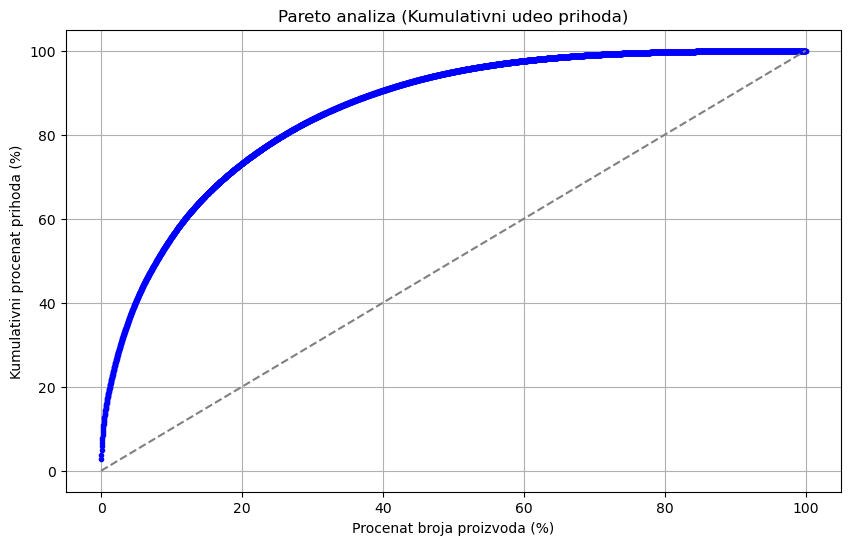

In [27]:
plt.figure(figsize=(10, 6))
plt.plot(
    cumulative_products_pct,
    cumulative,
    marker='.',
    linestyle='-',
    color='b',
)
plt.plot([0, 100], [0, 100], color='gray', linestyle='--')

plt.title('Pareto analiza (Kumulativni udeo prihoda)')
plt.xlabel('Procenat broja proizvoda (%)')
plt.ylabel('Kumulativni procenat prihoda (%)')
plt.grid(True)
plt.show()

In [ ]:
## This pareto graph indicate that small amount of product generate almost 80%of revenue.